# 14장 라벨 신뢰도 추정

13장의 Jev 오라클은 라벨과 함께 신뢰도를 돌려준다. 15장에서 「신뢰도가 낮은 라벨만 사람에게 보낸다」는 라우팅을 하려면 이 신뢰도가 실제로 맞을 확률을 잘 나타내야 한다. 이 장은 신뢰도를 얻는 방법을 비교하고, 신뢰도와 정답률이 얼마나 맞는지(보정) 재고 고친 뒤, 목표 정확도를 지키는 임계값을 정한다.

- 14.1 LLM 라벨 신뢰도의 정의
- 14.2 언어화 신뢰도(verbalized confidence)
- 14.3 자기일관성(self-consistency)
- 14.4 다중 샘플 합의와 프롬프트 앙상블
- 14.5 신뢰도 보정과 기대 보정 오차(ECE)
- 14.6 신뢰도 임계값 선택

모든 측정은 루프와 떼어 검증 집합 2,000개에서 한다. 요청은 13장에서 고른 설정(NSMC 스키마 S1 + 클래스 균형 예시 8개, YNAT 스키마 S2 + 클래스 균형 예시 7개)을 쓴다. Jev 호출에 필요한 키·주소·모델 이름은 `jupyter/.env` 에서만 읽는다.

### 공통 코드

2장에서 정의한 데이터 읽기, 학생 모델, 시뮬레이션 오라클, 루프, 지표 함수를 그대로 다시 싣는다. 노트북마다 필요한 코드를 모두 담는 규칙을 따른다.

In [1]:
# ── 환경 설정과 상수 ────
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from joblib import Parallel, delayed

SEEDS = [0, 1, 2, 3, 4]
N_INIT, K, BUDGET = 100, 50, 2000
ACCENT, INK, GRAY, GRAY2 = "#E32C24", "#1C1C1A", "#575753", "#8C8A85"
LABEL = {"acc": "정확도", "f1": "매크로 F1"}

# ── 데이터 읽기와 특징 추출 ────
def load_data(name):
    pool = pd.read_csv(f"data/{name}_pool.csv")
    test = pd.read_csv(f"data/{name}_test.csv")
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2,
                          max_features=50000, sublinear_tf=True)
    X_pool = vec.fit_transform(pool.text)          # 라벨을 쓰지 않으므로 누수가 아니다
    return dict(name=name, texts=pool.text.values, X_pool=X_pool, y_pool=pool.label.values,
                X_test=vec.transform(test.text), y_test=test.label.values,
                n_classes=pool.label.nunique())

DATA = {name: load_data(name) for name in ("nsmc", "ynat")}
for d in DATA.values():
    print(d["name"], "풀", d["X_pool"].shape, "시험", d["X_test"].shape, "클래스", d["n_classes"])

# ── 학생 모델 ────
def train_model(X, y, seed):
    return LogisticRegression(C=10.0, max_iter=1000, random_state=seed).fit(X, y)

def proba(model, X, n_classes):
    # 라벨 집합에 없는 클래스의 확률 열을 0으로 채워 열 수를 고정한다
    P = np.zeros((X.shape[0], n_classes))
    P[:, model.classes_] = model.predict_proba(X)
    return P

# ── 시뮬레이션 오라클 ────
def make_sim_oracle(y_true):
    # 정답 라벨과 신뢰도 1.0을 돌려준다. 13장의 Jev 오라클이 같은 자리에 들어온다
    return lambda idx, texts: (y_true[idx], np.ones(len(idx)))

# ── 능동 학습 루프 ────
def run_loop(query_fn, oracle_fn, data, seed, n_init=N_INIT, k=K, budget=BUDGET):
    rng = np.random.default_rng(seed)
    n = data["X_pool"].shape[0]
    idx_l = rng.choice(n, n_init, replace=False)
    y_l, _ = oracle_fn(idx_l, data["texts"][idx_l])
    idx_u = np.setdiff1d(np.arange(n), idx_l)
    log = []
    while True:
        model = train_model(data["X_pool"][idx_l], y_l, seed)                          # 1. train
        y_hat = model.predict(data["X_test"])                                             # 평가
        log.append(dict(seed=seed, n_labeled=len(idx_l), acc=accuracy_score(data["y_test"], y_hat),
                        f1=f1_score(data["y_test"], y_hat, average="macro"), t_query=np.nan))
        if len(idx_l) >= budget:
            break
        t0 = time.perf_counter()
        q = query_fn(model, data, idx_l, y_l, idx_u, min(k, budget - len(idx_l)), rng)   # 2. predict · 3. query
        log[-1]["t_query"] = time.perf_counter() - t0
        y_q, _ = oracle_fn(q, data["texts"][q])                                           # 4. label
        idx_l, y_l = np.r_[idx_l, q], np.r_[y_l, y_q]                                     # 5. update
        idx_u = np.setdiff1d(idx_u, q)
    return pd.DataFrame(log), idx_l

# ── 무작위 질의 함수 ────
def query_random(model, data, idx_l, y_l, idx_u, k, rng):
    return rng.choice(idx_u, k, replace=False)

# ── 지표와 실험 도구 ────
def alc(n, m, budget=BUDGET):
    # 라벨 수를 [n0, budget] → [0, 1]로 정규화한 사다리꼴 적분. n0은 첫 측정점이다
    keep = n <= budget
    u, m = (n[keep] - n[0]) / (budget - n[0]), m[keep]
    return np.sum(np.diff(u) * (m[1:] + m[:-1]) / 2)

def label_efficiency(n, m, m_target, budget=BUDGET):
    hit = n[m >= m_target]
    return budget / hit[0] if len(hit) else np.nan

def run_strategies(strategies, data, seeds=SEEDS, n_jobs=-1, **kw):
    # (전략, 시드) 조합을 CPU 코어에 나눠 돌린다. 시드마다 난수 생성기가 따로라 순차 실행과 결과가 같다
    oracle = make_sim_oracle(data["y_pool"])
    jobs = [(name, s) for name in strategies for s in seeds]
    out = Parallel(n_jobs=n_jobs)(delayed(run_loop)(strategies[name], oracle, data, s, **kw) for name, s in jobs)
    print(f"{data['name']:5s} {', '.join(strategies)} 완료")
    return pd.concat([df.assign(strategy=name) for (name, _), (df, _) in zip(jobs, out)], ignore_index=True)

def summarize(res, metric="f1", ref="Random", budget=BUDGET):
    target = res[res.strategy == ref].groupby("n_labeled")[metric].mean().loc[budget]
    rows = []
    for name, g in res.groupby("strategy", sort=False):
        alcs = [alc(d.n_labeled.values, d[metric].values, budget) for _, d in g.groupby("seed")]
        curve = g.groupby("n_labeled")[metric].mean()
        rows.append(dict(strategy=name, ALC=np.mean(alcs), ALC_std=np.std(alcs), final=curve.loc[budget],
                         LE=label_efficiency(curve.index.values, curve.values, target, budget),
                         t_query=g[g.n_labeled < budget].t_query.mean()))
    return pd.DataFrame(rows).round(4)

STYLES = [(ACCENT, "-"), (INK, "--"), (GRAY, "-."), (GRAY2, ":"), ("#2B6CB0", "-"), ("#9C6B30", "--")]

def plot_curves(res, metric, ax, title):
    for (name, g), (c, ls) in zip(res.groupby("strategy", sort=False), STYLES):
        s = g.groupby("n_labeled")[metric].agg(["mean", "std"]).fillna(0)
        ax.plot(s.index, s["mean"], color=c, ls=ls, lw=1.6, label=name)
        ax.fill_between(s.index, s["mean"] - s["std"], s["mean"] + s["std"], color=c, alpha=0.12)
    ax.set(title=title, xlabel="라벨 수", ylabel=LABEL[metric])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

nsmc 풀 (20000, 50000) 시험 (10000, 50000) 클래스 2
ynat 풀 (20000, 50000) 시험 (9107, 50000) 클래스 7


In [2]:
# ── Jev 호출 함수 ────
import os
import requests
from dotenv import load_dotenv
from concurrent.futures import ThreadPoolExecutor

load_dotenv(".env")                      # jupyter/.env — 키·주소·모델 이름은 여기에만 있다
print({n: bool(os.getenv(n)) for n in ("JEV_API_KEY", "JEV_BASE_URL", "JEV_MODEL")})   # 값은 출력하지 않는다

JEV = dict(key=os.environ["JEV_API_KEY"], url=os.environ["JEV_BASE_URL"].rstrip("/"), model=os.environ["JEV_MODEL"])
MAX_CONC = 5                             # 동시 호출 수
SESSION = requests.Session()

def mask(text):
    # 오류 메시지에 키·주소·모델 이름이 섞여 나오지 않도록 가린다
    for v in JEV.values():
        text = text.replace(v, "***")
    return text

def jev_ask(state, questions):
    # 판정 질문 묶음을 한 번 보내고 (질문 이름별 답, 입력 토큰, 출력 토큰)을 돌려준다
    body = dict(model=JEV["model"], state=state, questions=questions)
    for wait in (2, 4, 8, 16, 32, 64):                       # 일시 오류(429·5xx)는 잠시 쉬고 다시 보낸다
        r = SESSION.post(f"{JEV['url']}/v1/systemone", headers={"Authorization": f"Bearer {JEV['key']}"},
                         json=body, timeout=300)
        if r.status_code == 200:
            j = r.json()
            return j["answers"], j["usage"]["input_tokens"], j["usage"]["output_tokens"]
        time.sleep(wait)
    raise RuntimeError(mask(f"Jev 응답 {r.status_code}: {r.text[:300]}"))

{'JEV_API_KEY': True, 'JEV_BASE_URL': True, 'JEV_MODEL': True}


In [3]:
# ── 라벨 체계 ────
LABEL_NAMES = {"nsmc": ["부정", "긍정"],
               "ynat": ["IT과학", "경제", "사회", "생활문화", "세계", "스포츠", "정치"]}
LABEL_DESC = {"nsmc": {"부정": "영화를 부정적으로 평가한 리뷰", "긍정": "영화를 긍정적으로 평가한 리뷰"},
              "ynat": {"IT과학": "정보기술·과학 기사", "경제": "경제·산업·금융 기사", "사회": "사건·사고·사회 기사",
                       "생활문화": "생활·문화·건강·여행 기사", "세계": "국제·해외 기사", "스포츠": "스포츠 기사",
                       "정치": "정치·외교·북한 기사"}}
TASK = {"nsmc": "영화 리뷰의 감성", "ynat": "뉴스 기사 제목의 주제"}

In [4]:
# ── 검증 집합 ────
# 라벨 정확도·신뢰도는 루프와 떼어 검증 집합 2,000개에서 잰다. 시험 집합은 학생 모델 평가에만 쓴다
VAL = {name: pd.read_csv(f"data/{name}_val.csv") for name in DATA}
for name, v in VAL.items():
    print(name, "검증", len(v), "클래스별", np.bincount(v.label).tolist())

nsmc 검증 2000 클래스별 [1003, 997]
ynat 검증 2000 클래스별 [229, 268, 225, 252, 364, 339, 323]


13장의 요청 함수에 두 가지를 더한다. 지시문을 바꿔 쓰는 인자(`desc`, `task`, `reverse`)와, 문장마다 「라벨이 얼마나 분명한가」를 묻는 자기 평가 질문(`sure`)이다.

In [5]:
# ── 라벨 스키마와 요청 만들기 (13장 + 지시문 변형·자기 평가 질문) ────
CHUNK = 50                               # 요청 하나에 넣는 문장 수
TASK_SENT = {"nsmc": "영화 리뷰의 감성을 분류한다.", "ynat": "뉴스 기사 제목의 주제를 분류한다."}
RULES = {"nsmc": ["반어나 비꼼으로 칭찬하는 척하는 리뷰는 부정이다",
                  "칭찬과 불만이 섞이면 글쓴이의 최종 평가를 따른다",
                  "영화 밖의 이야기(배우, 다른 관객)라도 영화에 대한 태도가 드러나면 그 태도를 따른다"],
         "ynat": ["기업·산업·시장·금융·부동산은 경제다. IT 제품·통신·인터넷 서비스·과학 연구는 IT과학이다",
                  "사건·사고·교육·노동·법원·지역 소식은 사회다",
                  "국내 정치·국회·정당·외교·북한은 정치다. 외국 정부와 해외에서 일어난 일은 세계다",
                  "문화·연예·건강·여행·종교·생활 정보는 생활문화다",
                  "경기 결과·선수·구단·대회는 스포츠다"]}
# 지시문 변형 v1: 같은 뜻을 다른 말로 쓴 과제 문장과 라벨 설명
TASK_ALT = {"nsmc": "리뷰를 쓴 사람이 영화를 좋게 봤는지 나쁘게 봤는지 가린다.",
            "ynat": "기사 제목을 보고 어느 지면에 실릴 기사인지 가린다."}
LABEL_DESC_ALT = {"nsmc": {"부정": "영화가 별로였다는 리뷰", "긍정": "영화가 좋았다는 리뷰"},
                  "ynat": {"IT과학": "컴퓨터·인터넷·통신·과학 소식", "경제": "기업·시장·돈의 흐름에 관한 소식",
                           "사회": "사건·사고와 사회 문제", "생활문화": "생활 정보·문화·건강·여행",
                           "세계": "다른 나라 소식", "스포츠": "경기와 선수 소식", "정치": "정부·국회·정당·외교·북한 소식"}}
SURE_LEVELS = ["어느 라벨인지 알 수 없다", "두 라벨 사이에서 헷갈린다", "한 라벨에 기울지만 다른 라벨일 수 있다",
               "거의 분명하다", "의심할 여지 없이 분명하다"]

def schema_text(name, level, desc, task, names):
    lines = [f"과제: {task[name]}", "라벨:"]
    lines += [f"- {n}: {desc[name][n]}" if level >= 1 else f"- {n}" for n in names]
    lines += ["경계 규칙:"] + [f"- {r}" for r in RULES[name]] if level == 2 else []
    return "\n".join(lines)

def build_request(name, texts, schema=1, shots=(), desc=LABEL_DESC, task=TASK_SENT, reverse=False, sure=False):
    # reverse: 라벨 목록과 선택지 순서를 뒤집는다. sure: 문장마다 자기 평가 질문 sure_i를 더한다
    names = LABEL_NAMES[name][::-1] if reverse else LABEL_NAMES[name]
    one = lambda t: str(t).replace("\n", " ")
    parts = [schema_text(name, schema, desc, task, names)]
    parts += ["예시:\n" + "\n".join(f'- "{one(t)}" → {y}' for t, y in shots)] if len(shots) else []
    state = "\n\n".join(parts + ["분류할 문장:\n" + "\n".join(f"[{i}] {one(t)}" for i, t in enumerate(texts))])
    qs = {f"label_{i}": {"type": "choice", "instructions": f"[{i}]번 문장의 라벨", "criteria": {n: None for n in names}}
          for i in range(len(texts))}
    qs.update({f"sure_{i}": {"type": "score", "instructions": f"[{i}]번 문장의 라벨은 얼마나 분명한가?", "criteria": SURE_LEVELS}
               for i in range(len(texts))} if sure else {})
    return state, qs

In [6]:
# ── Jev 라벨 판정 ────
def jev_label(name, texts, cfg):
    # (선택지 확률 행렬, 답의 confidence, 자기 평가 점수, 묶음별 사용량). 자기 평가를 묻지 않았으면 점수는 NaN
    names = LABEL_NAMES[name]
    def one(s):
        state, qs = build_request(name, texts[s:s + CHUNK], **cfg)
        t0 = time.perf_counter()
        ans, a, b = jev_ask(state, qs)
        n = len(texts[s:s + CHUNK])
        P = [[ans[f"label_{i}"]["probabilities"].get(m, 0.0) for m in names] for i in range(n)]
        c = [ans[f"label_{i}"]["confidence"] for i in range(n)]
        sc = [ans.get(f"sure_{i}", {}).get("score", np.nan) for i in range(n)]
        return P, c, sc, dict(n_in=a, n_out=b, t=time.perf_counter() - t0, n=n)
    with ThreadPoolExecutor(MAX_CONC) as ex:
        out = list(ex.map(one, range(0, len(texts), CHUNK)))
    P = np.array([p for o in out for p in o[0]])
    flat = lambda j: np.array([v for o in out for v in o[j]])
    return P / P.sum(1, keepdims=True), flat(1), flat(2), pd.DataFrame([o[3] for o in out])

os.makedirs("results/ch14_parts", exist_ok=True)

def static_eval(name, key, cfg):
    # 검증 2,000개 판정을 key 이름으로 저장한다. 파일이 있으면 Jev를 부르지 않고 읽는다
    path = f"results/ch14_parts/static_{name}_{key}.csv"
    if os.path.exists(path):
        return pd.read_csv(path)
    v = VAL[name]
    P, c, sc, u = jev_label(name, v.text.values, cfg)
    df = pd.DataFrame(P, columns=[f"p{j}" for j in range(P.shape[1])]).assign(y=v.label.values, conf=c, sure=sc)
    df["n_in"] = np.repeat(u.n_in.values / u.n.values, u.n.values)
    df["t"] = np.repeat(u.t.values / u.n.values, u.n.values)
    df.to_csv(path, index=False)
    return df

PROBS = lambda df: df.filter(regex=r"^p\d").values

In [7]:
# ── 13장에서 고른 기본 요청 ────
BEST = {"nsmc": dict(schema=1, n=8), "ynat": dict(schema=2, n=7)}     # 13장: NSMC S1 + 균형 8, YNAT S2 + 균형 7

def init_idx(d, seed):
    return np.random.default_rng(seed).choice(d["X_pool"].shape[0], N_INIT, replace=False)

def shots_of(d, idx):
    return [(d["texts"][i], LABEL_NAMES[d["name"]][d["y_pool"][i]]) for i in idx]

def pick_bal(d, idx0, n, rng):
    y0 = d["y_pool"][idx0]
    pick = np.concatenate([rng.choice(idx0[y0 == c], n // d["n_classes"], replace=False) for c in range(d["n_classes"])])
    return rng.permutation(pick)

def base_cfg(name, shot_seed=0, **kw):
    # 시드 shot_seed의 초기 라벨 100개에서 클래스 균형 예시를 고른다. shot_seed = 0이면 13장 루프의 설정과 같다
    d = DATA[name]
    shots = shots_of(d, pick_bal(d, init_idx(d, shot_seed), BEST[name]["n"], np.random.default_rng(shot_seed)))
    return dict(schema=BEST[name]["schema"], shots=shots, **kw)

# 보정·임계값을 맞추는 절반(CAL)과 평가하는 절반(EVA)
perm = np.random.default_rng(0).permutation(len(VAL["nsmc"]))
CAL, EVA = perm[:1000], perm[1000:]

In [8]:
# ── 신뢰도 지표 ────
from sklearn.metrics import roc_auc_score

def ece(conf, ok, bins=10):
    b = np.minimum((conf * bins).astype(int), bins - 1)
    return sum(abs(ok[b == i].mean() - conf[b == i].mean()) * (b == i).mean() for i in range(bins) if (b == i).any())

def conf_metrics(yh, conf, y):
    ok = (yh == y).astype(float)
    return dict(acc=ok.mean(), ECE=ece(conf, ok), Brier=((conf - ok) ** 2).mean(), AUROC=roc_auc_score(ok, conf))

## 14.1 LLM 라벨 신뢰도의 정의

신뢰도 c(x)가 좋다는 것은 두 가지를 뜻한다. 첫째, 신뢰도가 높은 라벨일수록 더 자주 맞는다(구별력). 이것은 신뢰도로 정답과 오답을 가르는 AUROC로 잰다. 둘째, 신뢰도 0.8인 라벨들은 실제로 80% 맞는다(보정). 이것은 기대 보정 오차(ECE)와 브라이어 점수로 잰다. 15장 라우팅에는 구별력이 먼저 필요하다. 신뢰도 순서대로 사람에게 보낼 것이기 때문이다. 보정은 「임계값 0.9」 같은 숫자를 정답률로 읽으려 할 때 필요하다.

Jev는 텍스트를 생성하지 않으므로 다음 토큰 확률을 볼 수 없다. 대신 판정 API가 돌려주는 값을 쓴다. choice 질문의 답에는 선택지별 확률(`probabilities`)과 따로 매긴 신뢰도(`confidence`)가 함께 온다. 13장 첫 호출에서 두 값은 최대 0.49까지 달랐다.

신뢰도를 얻는 방법 넷을 비교한다.

| 방법 | 얻는 법 | 요청 수 |
|---|---|---|
| 선택지 확률·답 confidence | 기본 요청 한 번의 두 값 | 1 |
| 자기 평가 | 문장마다 「라벨이 얼마나 분명한가」(0~4)를 함께 묻는다 | 1(질문 2배) |
| 자기일관성 | 같은 요청을 5번 보낸다 | 5 |
| 프롬프트 앙상블 | 지시문을 바꾼 요청 5개를 한 번씩 보낸다 | 5 |

평가는 검증 집합을 반으로 나눠 한다. 보정과 임계값은 앞 절반(CAL)으로 맞추고, 모든 표는 뒤 절반(EVA)에서 잰다.

## 14.2 언어화 신뢰도(verbalized confidence)

생성형 LLM에서 언어화 신뢰도는 「몇 퍼센트 확신하는지」를 말로 답하게 한 값이다. Jev에서는 이것을 score 질문으로 묻는다. 문장마다 라벨 질문 `label_i` 옆에 `sure_i` 를 붙인다. 척도는 「어느 라벨인지 알 수 없다」(0)부터 「의심할 여지 없이 분명하다」(4)까지 다섯 단계이고, 기대 점수를 4로 나눠 0~1 신뢰도로 쓴다.

기본 요청(자기 평가 없음)과 자기 평가 요청을 한 번씩 보낸다. 기본 요청에서는 선택지 확률과 답 confidence 두 가지를 얻는다.

In [9]:
# ── 기본 요청과 자기 평가 요청 ────
runs = {}
for name in DATA:
    runs[name] = dict(rep0=static_eval(name, "rep0", base_cfg(name)), sure=static_eval(name, "sure", base_cfg(name, sure=True)))

def single_methods(name):
    r0, s = runs[name]["rep0"], runs[name]["sure"]
    return {"선택지 확률": (PROBS(r0).argmax(1), PROBS(r0).max(1), r0.n_in.mean(), PROBS(r0)),
            "답 confidence": (PROBS(r0).argmax(1), r0.conf.values, r0.n_in.mean(), None),
            "자기 평가": (PROBS(s).argmax(1), s.sure.values / 4, s.n_in.mean(), None)}

for name in DATA:
    y = VAL[name].label.values[EVA]
    t = pd.DataFrame({m: dict(conf_metrics(yh[EVA], c[EVA], y), conf=c[EVA].mean(), tok=tok)
                      for m, (yh, c, tok, _) in single_methods(name).items()}).T
    print(f"\n{name} 한 번 묻기 (EVA 1,000, tok = 문장당 입력 토큰)")
    print(t.round(4).to_string())
    r0, s = runs[name]["rep0"], runs[name]["sure"]
    print(f"{name} 상관(스피어만): 선택지 확률–답 confidence {pd.Series(PROBS(r0).max(1)).corr(r0.conf, method='spearman'):.3f}, "
          f"선택지 확률–자기 평가 {pd.Series(PROBS(s).max(1)).corr(s.sure, method='spearman'):.3f} | 자기 평가 점수 분포",
          np.percentile(s.sure, [0, 10, 50, 90, 100]).round(2))


nsmc 한 번 묻기 (EVA 1,000, tok = 문장당 입력 토큰)
                acc     ECE   Brier   AUROC    conf      tok
선택지 확률        0.909  0.0435  0.0758  0.7903  0.9335   81.693
답 confidence  0.909  0.0760  0.0958  0.7903  0.8671   81.693
자기 평가         0.908  0.1197  0.1102  0.7892  0.7883  187.493
nsmc 상관(스피어만): 선택지 확률–답 confidence 1.000, 선택지 확률–자기 평가 0.873 | 자기 평가 점수 분포 [0.08 1.68 3.5  3.96 4.  ]

ynat 한 번 묻기 (EVA 1,000, tok = 문장당 입력 토큰)
                acc     ECE   Brier   AUROC    conf       tok
선택지 확률        0.848  0.0460  0.1014  0.8299  0.8902  112.2035
답 confidence  0.848  0.0292  0.0997  0.8299  0.8719  112.2035
자기 평가         0.844  0.0725  0.1113  0.8245  0.7886  218.0035
ynat 상관(스피어만): 선택지 확률–답 confidence 1.000, 선택지 확률–자기 평가 0.883 | 자기 평가 점수 분포 [1.09 2.36 3.21 3.84 3.97]


## 14.3 자기일관성(self-consistency)

자기일관성은 같은 질문을 여러 번 해서 답이 얼마나 일치하는지를 신뢰도로 쓴다. 생성형 LLM에서는 temperature를 올려 서로 다른 답을 뽑는다. Jev API에는 temperature가 없다. 대신 3부에서 본 것처럼 같은 요청에도 답이 조금씩 흔들린다. 이 흔들림을 표본으로 쓴다.

같은 기본 요청을 네 번 더 보내 모두 다섯 번의 답을 얻는다. 먼저 흔들림의 크기를 본다. 라벨이 바뀐 문장의 비율, 확률의 최대 차이, 다섯 번이 모두 같은 라벨을 낸 문장의 비율이다.

In [10]:
# ── 같은 요청 반복 ────
for name in DATA:
    runs[name].update({f"rep{r}": static_eval(name, f"rep{r}", base_cfg(name)) for r in range(1, 5)})

def spread(dfs):
    # 첫 실행 대비 라벨이 바뀐 비율·확률 최대 차이, 모두 같은 라벨인 문장 비율
    P0 = PROBS(dfs[0])
    flips = [(PROBS(d).argmax(1) != P0.argmax(1)).mean() for d in dfs[1:]]
    dmax = [np.abs(PROBS(d) - P0).max() for d in dfs[1:]]
    votes = np.stack([PROBS(d).argmax(1) for d in dfs])
    return dict(flip_mean=np.mean(flips), flip_max=np.max(flips), dP_max=np.max(dmax),
                dP_mean=np.mean([np.abs(PROBS(d) - P0).max(1).mean() for d in dfs[1:]]),
                unanimous=(votes == votes[0]).all(0).mean())

for name in DATA:
    print(name, "같은 요청 5번:", {k: round(v, 4) for k, v in spread([runs[name][f"rep{r}"] for r in range(5)]).items()})

nsmc 같은 요청 5번: {'flip_mean': 0.0061, 'flip_max': 0.0065, 'dP_max': 0.63, 'dP_mean': 0.0095, 'unanimous': 0.9865}
ynat 같은 요청 5번: {'flip_mean': 0.0121, 'flip_max': 0.0145, 'dP_max': 0.83, 'dP_mean': 0.0182, 'unanimous': 0.9755}


다섯 번의 답을 두 방식으로 합친다. 평균 확률은 다섯 확률 벡터의 평균이고, 그 최댓값을 신뢰도로 쓴다. 득표율은 평균 확률이 가장 큰 라벨에 다섯 번 중 몇 번 표가 갔는지다. K를 3과 5로 바꿔 요청 수를 늘린 만큼 신뢰도가 나아지는지 본다.

In [11]:
# ── 반복 답 합치기 ────
def combine(dfs, label):
    Pm = np.mean([PROBS(d) for d in dfs], axis=0)
    yh = Pm.argmax(1)
    share = (np.stack([PROBS(d).argmax(1) for d in dfs]) == yh).mean(0)
    tok = sum(d.n_in.mean() for d in dfs)
    return {f"{label} 득표율": (yh, share, tok, None), f"{label} 평균 확률": (yh, Pm.max(1), tok, Pm)}

def sc_methods(name):
    reps = [runs[name][f"rep{r}"] for r in range(5)]
    return {**combine(reps[:3], "자기일관성 K=3"), **combine(reps, "자기일관성 K=5")}

for name in DATA:
    y = VAL[name].label.values[EVA]
    t = pd.DataFrame({m: dict(conf_metrics(yh[EVA], c[EVA], y), tok=tok)
                      for m, (yh, c, tok, _) in {**single_methods(name), **sc_methods(name)}.items() if m != "자기 평가"}).T
    print(f"\n{name} 자기일관성 (EVA 1,000)")
    print(t.round(4).to_string())


nsmc 자기일관성 (EVA 1,000)
                   acc     ECE   Brier   AUROC      tok
선택지 확률           0.909  0.0435  0.0758  0.7903   81.693
답 confidence     0.909  0.0760  0.0958  0.7903   81.693
자기일관성 K=3 득표율    0.907  0.0903  0.0914  0.5139  245.079
자기일관성 K=3 평균 확률  0.907  0.0443  0.0760  0.7983  245.079
자기일관성 K=5 득표율    0.907  0.0912  0.0906  0.5300  408.465
자기일관성 K=5 평균 확률  0.907  0.0440  0.0758  0.8027  408.465

ynat 자기일관성 (EVA 1,000)
                   acc     ECE   Brier   AUROC       tok
선택지 확률           0.848  0.0460  0.1014  0.8299  112.2035
답 confidence     0.848  0.0292  0.0997  0.8299  112.2035
자기일관성 K=3 득표율    0.848  0.1447  0.1467  0.5303  336.6105
자기일관성 K=3 평균 확률  0.848  0.0444  0.1023  0.8312  336.6105
자기일관성 K=5 득표율    0.848  0.1438  0.1465  0.5282  561.0175
자기일관성 K=5 평균 확률  0.848  0.0434  0.1025  0.8313  561.0175


## 14.4 다중 샘플 합의와 프롬프트 앙상블

같은 요청의 흔들림이 작으면 반복해도 얻는 것이 적다. 프롬프트 앙상블은 요청 자체를 바꿔 서로 다른 판단을 끌어낸다. 변형은 다섯이다.

| 변형 | 바꾼 것 |
|---|---|
| v0 기본 | 13장 설정 그대로(14.3절의 첫 실행) |
| v1 바꿔 쓴 설명 | 과제 문장과 라벨 설명을 같은 뜻의 다른 말로 |
| v2 라벨 순서 반대 | 스키마의 라벨 목록과 선택지 순서를 뒤집음 |
| v3·v4 예시 묶음 | 시드 1·2의 초기 라벨 100개에서 고른 클래스 균형 예시 |

v3·v4는 13장에서 토큰을 아끼려고 돌리지 않은 「예시 묶음의 흔들림」도 함께 보여 준다.

In [12]:
# ── 지시문 변형 ────
VARIANTS = {"v1 바꿔 쓴 설명": dict(desc=LABEL_DESC_ALT, task=TASK_ALT), "v2 라벨 순서 반대": dict(reverse=True),
            "v3 예시 묶음 1": dict(shot_seed=1), "v4 예시 묶음 2": dict(shot_seed=2)}
for name in DATA:
    runs[name].update({k: static_eval(name, k.split()[0], base_cfg(name, **cfg)) for k, cfg in VARIANTS.items()})

def ens_methods(name):
    return combine([runs[name]["rep0"]] + [runs[name][k] for k in VARIANTS], "프롬프트 앙상블")

for name in DATA:
    y = VAL[name].label.values[EVA]
    acc = {k: (PROBS(runs[name][k]).argmax(1)[EVA] == y).mean() for k in ["rep0", *VARIANTS]}
    print(f"\n{name} 변형별 라벨 정확도 (EVA):", {k: round(v, 4) for k, v in acc.items()})
    print(name, "변형 5개:", {k: round(v, 4) for k, v in spread([runs[name]["rep0"]] + [runs[name][k] for k in VARIANTS]).items()})


nsmc 변형별 라벨 정확도 (EVA): {'rep0': 0.909, 'v1 바꿔 쓴 설명': 0.907, 'v2 라벨 순서 반대': 0.909, 'v3 예시 묶음 1': 0.898, 'v4 예시 묶음 2': 0.904}
nsmc 변형 5개: {'flip_mean': 0.0154, 'flip_max': 0.019, 'dP_max': 0.8, 'dP_mean': 0.0161, 'unanimous': 0.9665}

ynat 변형별 라벨 정확도 (EVA): {'rep0': 0.848, 'v1 바꿔 쓴 설명': 0.851, 'v2 라벨 순서 반대': 0.844, 'v3 예시 묶음 1': 0.839, 'v4 예시 묶음 2': 0.844}
ynat 변형 5개: {'flip_mean': 0.0306, 'flip_max': 0.0395, 'dP_max': 0.95, 'dP_mean': 0.0355, 'unanimous': 0.9195}


In [13]:
# ── 방법 비교 (표 14.1) ────
def all_methods(name):
    return {**single_methods(name), **sc_methods(name), **ens_methods(name)}

tab = {}
for name in DATA:
    y = VAL[name].label.values[EVA]
    tab[name] = pd.DataFrame({m: dict(conf_metrics(yh[EVA], c[EVA], y), tok=tok) for m, (yh, c, tok, _) in all_methods(name).items()}).T
    print(f"\n{name} 신뢰도 방법 비교 (EVA 1,000, tok = 문장당 입력 토큰)")
    print(tab[name].round(4).to_string())


nsmc 신뢰도 방법 비교 (EVA 1,000, tok = 문장당 입력 토큰)
                   acc     ECE   Brier   AUROC      tok
선택지 확률           0.909  0.0435  0.0758  0.7903   81.693
답 confidence     0.909  0.0760  0.0958  0.7903   81.693
자기 평가            0.908  0.1197  0.1102  0.7892  187.493
자기일관성 K=3 득표율    0.907  0.0903  0.0914  0.5139  245.079
자기일관성 K=3 평균 확률  0.907  0.0443  0.0760  0.7983  245.079
자기일관성 K=5 득표율    0.907  0.0912  0.0906  0.5300  408.465
자기일관성 K=5 평균 확률  0.907  0.0440  0.0758  0.8027  408.465
프롬프트 앙상블 득표율     0.906  0.0862  0.0880  0.5746  406.725
프롬프트 앙상블 평균 확률   0.906  0.0414  0.0755  0.8051  406.725

ynat 신뢰도 방법 비교 (EVA 1,000, tok = 문장당 입력 토큰)
                   acc     ECE   Brier   AUROC       tok
선택지 확률           0.848  0.0460  0.1014  0.8299  112.2035
답 confidence     0.848  0.0292  0.0997  0.8299  112.2035
자기 평가            0.844  0.0725  0.1113  0.8245  218.0035
자기일관성 K=3 득표율    0.848  0.1447  0.1467  0.5303  336.6105
자기일관성 K=3 평균 확률  0.848  0.0444  0.1023  0.8312  336.6105
자기일관성 K=

## 14.5 신뢰도 보정과 기대 보정 오차(ECE)

신뢰도를 10개 구간으로 나누고 구간마다 평균 신뢰도와 실제 정답률의 차이를 구간 크기로 가중 평균한 것이 ECE다. 신뢰도 도표는 구간별 (평균 신뢰도, 정답률)을 찍은 그림이고, 대각선에 붙을수록 보정이 잘 된 것이다.

사후 보정은 두 가지를 쓴다.

- 온도 스케일링: 확률 벡터의 로그를 온도 T로 나눠 다시 정규화한다. 확률 벡터가 있는 방법(선택지 확률, 평균 확률)에만 쓸 수 있다. 여기의 T는 보정용 매개변수이고 API의 temperature와 상관없다.
- 등위 회귀(isotonic regression): 신뢰도를 정답 여부에 맞추는 단조 증가 함수를 배운다. 모든 방법에 쓸 수 있다.

둘 다 CAL에서 맞추고 EVA에서 잰다. 둘 다 순서를 바꾸지 않으므로 AUROC는 그대로다(등위 회귀는 동점을 만들어 조금 바뀔 수 있다).

In [14]:
# ── 사후 보정 ────
from scipy.optimize import minimize_scalar
from sklearn.isotonic import IsotonicRegression

def temp_scale(P, y):
    # CAL에서 음의 로그 우도를 최소로 하는 T를 찾고 전체에 적용한 신뢰도를 돌려준다
    L = np.log(P + 1e-12)
    soft = lambda T: np.exp(L / T) / np.exp(L / T).sum(1, keepdims=True)
    T = minimize_scalar(lambda T: -np.log(soft(T)[CAL, y[CAL]] + 1e-12).mean(), bounds=(0.05, 20), method="bounded").x
    return soft(T).max(1), T

def iso_scale(c, ok):
    return IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(c[CAL], ok[CAL]).predict(c)

calib = {}
for name in DATA:
    y = VAL[name].label.values
    rows = {}
    for m, (yh, c, tok, P) in all_methods(name).items():
        ok = (yh == y).astype(float)
        ct, T = temp_scale(P, y) if P is not None else (None, np.nan)
        ci = iso_scale(c, ok)
        rows[m] = dict(ECE=ece(c[EVA], ok[EVA]), T=T, ECE_temp=ece(ct[EVA], ok[EVA]) if ct is not None else np.nan,
                       ECE_iso=ece(ci[EVA], ok[EVA]), AUROC_iso=roc_auc_score(ok[EVA], ci[EVA]))
        calib[(name, m)] = (c, ci, ok)
    print(f"\n{name} 보정 전후 ECE (CAL로 맞추고 EVA에서 잼)")
    print(pd.DataFrame(rows).T.round(4).to_string())


nsmc 보정 전후 ECE (CAL로 맞추고 EVA에서 잼)
                    ECE       T  ECE_temp  ECE_iso  AUROC_iso
선택지 확률           0.0435  3.7058    0.1097   0.0263     0.7766
답 confidence     0.0760     NaN       NaN   0.0263     0.7766
자기 평가            0.1197     NaN       NaN   0.0249     0.7903
자기일관성 K=3 득표율    0.0903     NaN       NaN   0.0186     0.5139
자기일관성 K=3 평균 확률  0.0443  3.5341    0.1071   0.0214     0.7992
자기일관성 K=5 득표율    0.0912     NaN       NaN   0.0195     0.5301
자기일관성 K=5 평균 확률  0.0440  3.4882    0.1035   0.0229     0.7961
프롬프트 앙상블 득표율     0.0862     NaN       NaN   0.0267     0.5746
프롬프트 앙상블 평균 확률   0.0414  2.4458    0.0681   0.0290     0.8027



ynat 보정 전후 ECE (CAL로 맞추고 EVA에서 잼)
                    ECE       T  ECE_temp  ECE_iso  AUROC_iso
선택지 확률           0.0460  2.8374    0.1274   0.0154     0.8234
답 confidence     0.0292     NaN       NaN   0.0154     0.8234
자기 평가            0.0725     NaN       NaN   0.0245     0.8195
자기일관성 K=3 득표율    0.1447     NaN       NaN   0.0120     0.5303
자기일관성 K=3 평균 확률  0.0444  2.3864    0.1109   0.0233     0.8312
자기일관성 K=5 득표율    0.1438     NaN       NaN   0.0104     0.5279
자기일관성 K=5 평균 확률  0.0434  2.3562    0.1131   0.0217     0.8296
프롬프트 앙상블 득표율     0.1310     NaN       NaN   0.0216     0.5829
프롬프트 앙상블 평균 확률   0.0389  2.0436    0.0865   0.0374     0.8246


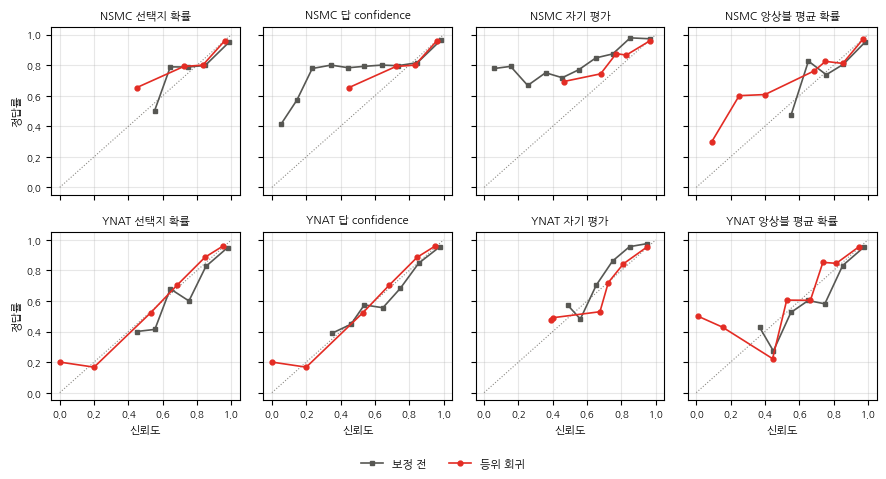

In [15]:
# ── 신뢰도 도표 ────
SHOW = ["선택지 확률", "답 confidence", "자기 평가", "프롬프트 앙상블 평균 확률"]

def reliability(c, ok, bins=10):
    b = np.minimum((c * bins).astype(int), bins - 1)
    keep = [i for i in range(bins) if (b == i).sum() >= 5]
    return np.array([c[b == i].mean() for i in keep]), np.array([ok[b == i].mean() for i in keep])

fig, axes = plt.subplots(2, 4, figsize=(9, 4.8), sharex=True, sharey=True)
for row, name in zip(axes, DATA):
    for ax, m in zip(row, SHOW):
        c, ci, ok = calib[(name, m)]
        ax.plot([0, 1], [0, 1], color=GRAY2, lw=0.8, ls=":")
        for cc, col, mk, lab in ((c, GRAY, "s", "보정 전"), (ci, ACCENT, "o", "등위 회귀")):
            xb, yb = reliability(cc[EVA], ok[EVA])
            ax.plot(xb, yb, color=col, marker=mk, ms=3.5, lw=1.2, label=lab)
        ax.set_title(f"{name.upper()} {m.replace('프롬프트 앙상블 ', '앙상블 ')}", fontsize=8)
        ax.grid(alpha=0.3)
        ax.tick_params(labelsize=7)
for ax in axes[1]:
    ax.set_xlabel("신뢰도", fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("정답률", fontsize=8)
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, fontsize=8, loc="lower center", ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig("out/ch14_reliability.png", dpi=200)

## 14.6 신뢰도 임계값 선택

신뢰도가 τ 이상인 라벨만 받아들이고 나머지를 사람에게 보내면, 받아들인 라벨의 정확도는 올라가고 받아들이는 비율(커버리지)은 내려간다. 커버리지–정확도 곡선은 신뢰도 순서대로 위에서부터 받아들일 때 이 둘의 관계를 그린다.

목표 정확도 α를 정하면 CAL에서 「받아들인 라벨의 정확도가 α 이상인 가장 낮은 τ」를 고른다. 그 τ를 EVA에 적용해 실제 정확도와 커버리지를 확인한다. 목표는 13장의 Jev 라벨 정확도(NSMC 약 0.90, YNAT 약 0.84)보다 높게 잡는다.

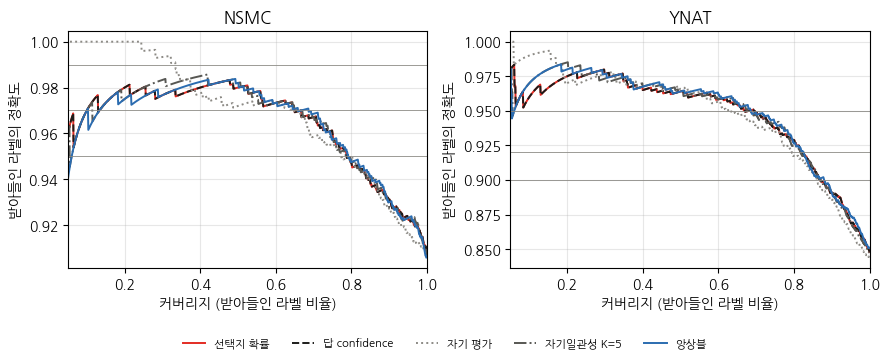

In [16]:
# ── 커버리지–정확도 곡선 ────
CURVE = ["선택지 확률", "답 confidence", "자기 평가", "자기일관성 K=5 평균 확률", "프롬프트 앙상블 평균 확률"]
STY = [(ACCENT, "-"), (INK, "--"), (GRAY2, ":"), (GRAY, "-."), ("#2B6CB0", "-")]
ALPHA = {"nsmc": (0.95, 0.97, 0.99), "ynat": (0.90, 0.92, 0.95)}

def cov_curve(c, ok):
    o = np.argsort(-c, kind="stable")
    return np.arange(1, len(c) + 1) / len(c), np.cumsum(ok[o]) / np.arange(1, len(c) + 1)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, name in zip(axes, DATA):
    for m, (col, ls) in zip(CURVE, STY):
        c, _, ok = calib[(name, m)]
        x, a = cov_curve(c[EVA], ok[EVA])
        ax.plot(x, a, color=col, ls=ls, lw=1.4, label=m.replace("프롬프트 앙상블", "앙상블").replace(" 평균 확률", ""))
    for al in ALPHA[name]:
        ax.axhline(al, color=GRAY2, lw=0.6)
    ax.set(title=name.upper(), xlabel="커버리지 (받아들인 라벨 비율)", ylabel="받아들인 라벨의 정확도", xlim=(0.05, 1))
    ax.grid(alpha=0.3)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, fontsize=8, loc="lower center", ncol=5, frameon=False)
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig("out/ch14_coverage.png", dpi=200)

In [17]:
# ── 목표 정확도의 임계값 (표 14.2) ────
def pick_tau(c, ok, alpha):
    # 위에서부터 받아들였을 때 정확도가 alpha 이상인 가장 긴 구간의 마지막 신뢰도
    o = np.argsort(-c, kind="stable")
    acc = np.cumsum(ok[o]) / np.arange(1, len(c) + 1)
    good = np.where(acc >= alpha)[0]
    return c[o][good.max()] if len(good) else np.inf

rows = []
for name in DATA:
    for m in CURVE:
        c, _, ok = calib[(name, m)]
        for al in ALPHA[name]:
            tau = pick_tau(c[CAL], ok[CAL], al)
            keep = c[EVA] >= tau
            rows.append(dict(data=name, method=m, alpha=al, tau=tau, coverage=keep.mean(),
                             acc=ok[EVA][keep].mean() if keep.any() else np.nan))
thr = pd.DataFrame(rows)
for name in DATA:
    print(f"\n{name} 목표 정확도별 τ (CAL에서 고름)와 EVA의 커버리지·정확도")
    print(thr[thr.data == name].pivot_table(index="method", columns="alpha", values=["tau", "coverage", "acc"], sort=False).round(3).to_string())


nsmc 목표 정확도별 τ (CAL에서 고름)와 EVA의 커버리지·정확도
                   tau              coverage                  acc              
alpha             0.95   0.97  0.99     0.95   0.97   0.99   0.95   0.97   0.99
method                                                                         
선택지 확률           0.890  0.970  1.00    0.798  0.672  0.437  0.947  0.967  0.982
답 confidence     0.780  0.940  1.00    0.798  0.672  0.437  0.947  0.967  0.982
자기 평가            0.620  0.775  0.99    0.807  0.638  0.108  0.947  0.970  1.000
자기일관성 K=5 평균 확률  0.898  0.964  1.00    0.788  0.673  0.406  0.949  0.967  0.985
프롬프트 앙상블 평균 확률   0.894  0.956  1.00    0.789  0.699  0.384  0.952  0.969  0.982

ynat 목표 정확도별 τ (CAL에서 고름)와 EVA의 커버리지·정확도
                   tau               coverage                  acc              
alpha             0.90   0.92   0.95     0.90   0.92   0.95   0.90   0.92   0.95
method                                                                          
선택지 확률           0.740  0.840  0.

15장 라우팅은 토큰을 아끼려고 요청 한 번으로 얻는 신뢰도만 쓴다. 선택지 확률과 답 confidence 가운데 두 데이터의 평균 AUROC가 높은 쪽을 고른다. 14.2절에서 두 값의 순위 상관이 1이었으므로 AUROC가 같으면 평균 ECE가 낮은 쪽을 고른다. 그리고 목표 정확도(NSMC 0.97, YNAT 0.92)의 τ를 15장의 기본값으로 넘긴다.

In [18]:
# ── 15장으로 넘길 신뢰도와 임계값 ────
single = ["선택지 확률", "답 confidence"]
au = {m: round(np.mean([tab[n].loc[m, "AUROC"] for n in DATA]), 4) for m in single}
ec = {m: round(np.mean([tab[n].loc[m, "ECE"] for n in DATA]), 4) for m in single}
ROUTE_CONF = max(single, key=lambda m: (au[m], -ec[m]))
print("평균 ECE:", ec)
TARGET = {"nsmc": 0.97, "ynat": 0.92}
print("평균 AUROC:", {m: round(v, 4) for m, v in au.items()}, "→ 15장 라우팅 신뢰도:", ROUTE_CONF)
for name in DATA:
    r = thr[(thr.data == name) & (thr.method == ROUTE_CONF) & (thr.alpha == TARGET[name])].iloc[0]
    print(f"{name}: 목표 {TARGET[name]} → τ = {r.tau:.4f}, EVA 커버리지 {r.coverage:.3f}, 정확도 {r.acc:.4f}")

평균 ECE: {'선택지 확률': 0.0447, '답 confidence': 0.0526}
평균 AUROC: {'선택지 확률': 0.8101, '답 confidence': 0.8101} → 15장 라우팅 신뢰도: 선택지 확률
nsmc: 목표 0.97 → τ = 0.9700, EVA 커버리지 0.672, 정확도 0.9673
ynat: 목표 0.92 → τ = 0.8400, EVA 커버리지 0.750, 정확도 0.9373


In [19]:
# ── 이 장이 쓴 Jev 입력 토큰 ────
import glob
files = [f for f in glob.glob("results/ch14_parts/*.csv") if not f.endswith(("_picks.csv", "_log.csv"))]
total = sum(pd.read_csv(f).filter(regex="^n_in").sum().sum() for f in files)
print(f"결과 파일에 기록된 Jev 입력 토큰 합: {total:,.0f}")

결과 파일에 기록된 Jev 입력 토큰 합: 4,296,730
